# Avaliação final: frequência de sinistros por apólice

**O problema.** Uma seguradora de automóveis precisa estimar quantos sinistros esperar por 100 apólices-ano em perfis diferentes de veículo, condutor e região. A duração da cobertura varia de poucos dias a mais de um ano.

**Por que a calibração por segmento importa.** Um modelo pode acertar o total e, ainda assim, errar sistematicamente em grupos específicos, por exemplo nas coberturas muito curtas. Um erro agregado pequeno pode esconder desvios grandes e de sinais opostos entre segmentos.

**A pergunta.** No benchmark francês `freMTPL2freq`, o Poisson com offset de exposição fixo, congelado na etapa 4 antes da avaliação no teste, supera a taxa global de referência nos registros reservados para essa avaliação? E onde as taxas previstas se afastam das observadas por faixa de exposição, idade do veículo e região?

Este notebook apresenta a avaliação final única da partição de **teste**, executada uma vez por `python -m freq_sinistros stage5` depois de verificações de integridade. Cada seção segue a sequência pergunta → execução → insights. As conclusões são restritas ao benchmark. `production_eligible` permanece falso.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "pt_br"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
out5 = artifacts.load_stage5(ROOT)

## 1. Origem e integridade

**Pergunta.** A avaliação usou o modelo, o roteiro e o código aprovados, com a população de teste prevista, e os agregados apresentados são os da execução oficial?

In [2]:
display(pd.Series(artifacts.verify_stage5(ROOT)["checks"], name="ok"))
display(artifacts.gate_checks(out5))
display(artifacts.run_summary(out5))

status_completed               True
files_match_checksums          True
frozen_model_matches_record    True
script_matches_record          True
integrity_gate_ok              True
test_rows_match_stage2         True
reconciliation_ok              True
single_official_run_lock       True
Name: ok, dtype: bool

arff_sha256                             True
assignments_sha256                      True
code_modules_match_frozen               True
frozen_model_sha256_approved            True
module_arff_approved                    True
module_freeze_approved                  True
module_profiles_approved                True
partition_config_sha256                 True
production_eligible_false               True
protocol_config_sha256                  True
stage3_coefficients_sha256              True
stage3_comparison_config_sha256         True
stage3_intervals_sha256                 True
stage3_preprocessing_sha256             True
stage3_protocol_amendment_sha256        True
stage3_validation_metrics_sha256        True
stage5_script_sha256_approved           True
verify_freeze_code_modules_unchanged    True
verify_freeze_exit_0                    True
verify_freeze_ok                        True
Name: ok, dtype: bool

status                                                                   completed
test_rows                                                                   101859
policy_years                                                           53,839.0932
observed_claims                                                         5,415.0000
observed_zeros                                                               96726
wall_s                                                                     88.4740
peak_rss_mib                                                              236.4000
bootstrap_replicas                                                            1000
bootstrap_seed                                                            20261121
frozen_model_sha256_approved     8ac94b7e59e55becdd0319f05f9d958483ea4042dc0aba...
stage5_script_sha256_approved    c0365ad5566e32e5099c48bb1d007367e646ce63ee8b04...
test_ids_sha256                  11808b8102160e12da25942da6ae0d841919600d64a1a7...
dtyp

### Insights

O portão de integridade foi satisfeito antes de as linhas de teste serem disponibilizadas ao avaliador (a verificação prévia do congelamento usa o leitor do ARFF integral, mas devolve somente a validação): os SHA-256 do modelo congelado e do roteiro conferem com os valores aprovados, o ARFF, as atribuições e os arquivos de origem conferem com o modelo, e os módulos de código conferem com os registrados. A execução oficial avaliou 101.859 registros de teste (53.839,09 apólices-ano, 5.415 sinistros e 96.726 zeros), em uma única execução protegida por trava, criada depois do portão e antes da disponibilização do teste; o número de linhas conferido se refere às linhas disponibilizadas ao avaliador, não à leitura física do ARFF. Os agregados são verificados aqui sem reler o ARFF, e nenhuma linha de teste é persistida.

## 2. Comparação primária

**Pergunta.** O Poisson congelado tem desvio médio de Poisson menor que a taxa global nas mesmas linhas de teste, com contagens e exposições originais? A diferença pareada Poisson − taxa global usa 1.000 réplicas bootstrap por `IDpol` (semente 20261121) e, como sensibilidade, por chave de perfil.

,candidato,registros,exposição,sinistros observados,sinistros previstos,observed_rate_per_100,predicted_rate_per_100,taxa prevista − observada,desvio médio de Poisson,log-verossimilhança média
0,poisson,101859,"53,839.0932",5415,"5,442.1495",10.0577,10.1082,0.0504,0.3190,-0.2107
1,global,101859,"53,839.0932",5415,"5,429.3637",10.0577,10.0844,0.0267,0.3308,-0.2166


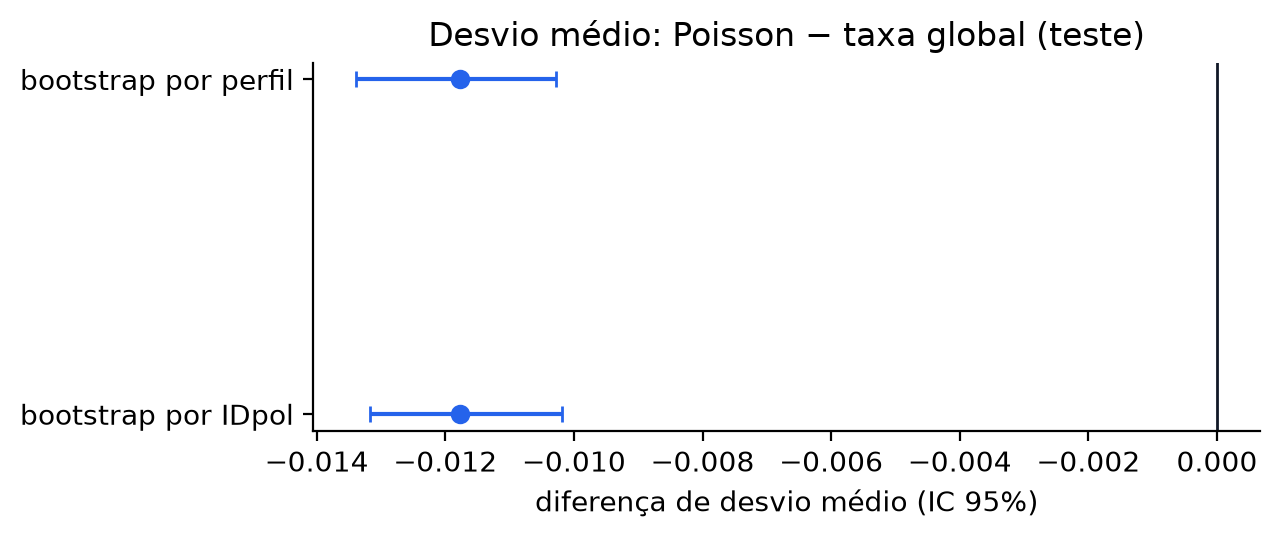

In [3]:
display(artifacts.metrics_view(out5, LANG))
plots.show(plots.plot_paired_difference(out5["test_intervals"], LANG))

### Insights

O desvio médio é 0,31902 no Poisson e 0,33079 na taxa global. A diferença pareada é -0,01177 (IC 95% -0,01317 a -0,01018; valores negativos favorecem o Poisson), e o bootstrap por perfil dá -0,01338 a -0,01028. Os dois intervalos ficam inteiramente abaixo de zero, de modo que o teste sustenta um ganho do Poisson sobre a taxa global na métrica primária. Esses intervalos são condicionados aos modelos ajustados e não incluem a variabilidade do ajuste.

No total, a taxa observada é 10,058 por 100 apólices-ano; a prevista é 10,108 (Poisson) e 10,084 (taxa global), com diferenças de 0,050 e 0,027. Cada intervalo de 95% se refere à diferença prevista − observada de um candidato: de -0,233 a 0,317 no Poisson e de -0,253 a 0,288 na taxa global, e ambos incluem zero. Esses intervalos individuais não testam equivalência entre os candidatos nem comparam seus erros absolutos, cujos valores pontuais são 0,050 (Poisson) e 0,027 (taxa global). O ganho confirmado é no desvio médio.

## 3. Calibração por faixa de exposição

**Pergunta.** Como as taxas previstas se comparam às observadas por faixa de exposição, e o comportamento observado em validação se repete no teste? As diferenças são prevista − observada, por 100 apólices-ano, calculadas com a exposição total de cada faixa e as previsões diretas; a faixa `(0; 0,02]` permanece visível e segmentos com menos de 500 registros ou 25 apólices-ano são sinalizados.

,segmento,registros,apólices-ano,sinistros observados,sinistros previstos,taxa observada por 100,taxa prevista por 100,prevista − observada,IC inf.,IC sup.,baixo suporte
0,"(0, 0.02]",2921,32.0932,82,4.5065,255.5058,14.0418,-241.4641,-296.6559,-190.3120,False
1,"(0.02, 0.08]",14341,916.9000,365,113.7112,39.8080,12.4017,-27.4063,-31.5899,-23.3945,False
2,"(0.08, 0.25]",16168,"2,788.5800",603,335.8947,21.6239,12.0454,-9.5785,-11.3882,-7.9628,False
3,"(0.25, 0.50]",19859,"7,789.0700",1012,888.4094,12.9926,11.4058,-1.5867,-2.4217,-0.7464,False
4,"(0.50, 0.75]",13877,"8,791.4200",952,"1,002.5454",10.8287,11.4037,0.5749,-0.1218,1.3333,False
5,"(0.75, 1)",9300,"8,108.0300",671,884.3093,8.2757,10.9066,2.6308,1.9811,3.2746,False
6,= 1,25222,"25,222.0000",1712,"2,191.1626",6.7877,8.6875,1.8998,1.5455,2.2113,False
7,> 1,171,191.0000,18,21.6106,9.4241,11.3144,1.8904,NaN,NaN,True


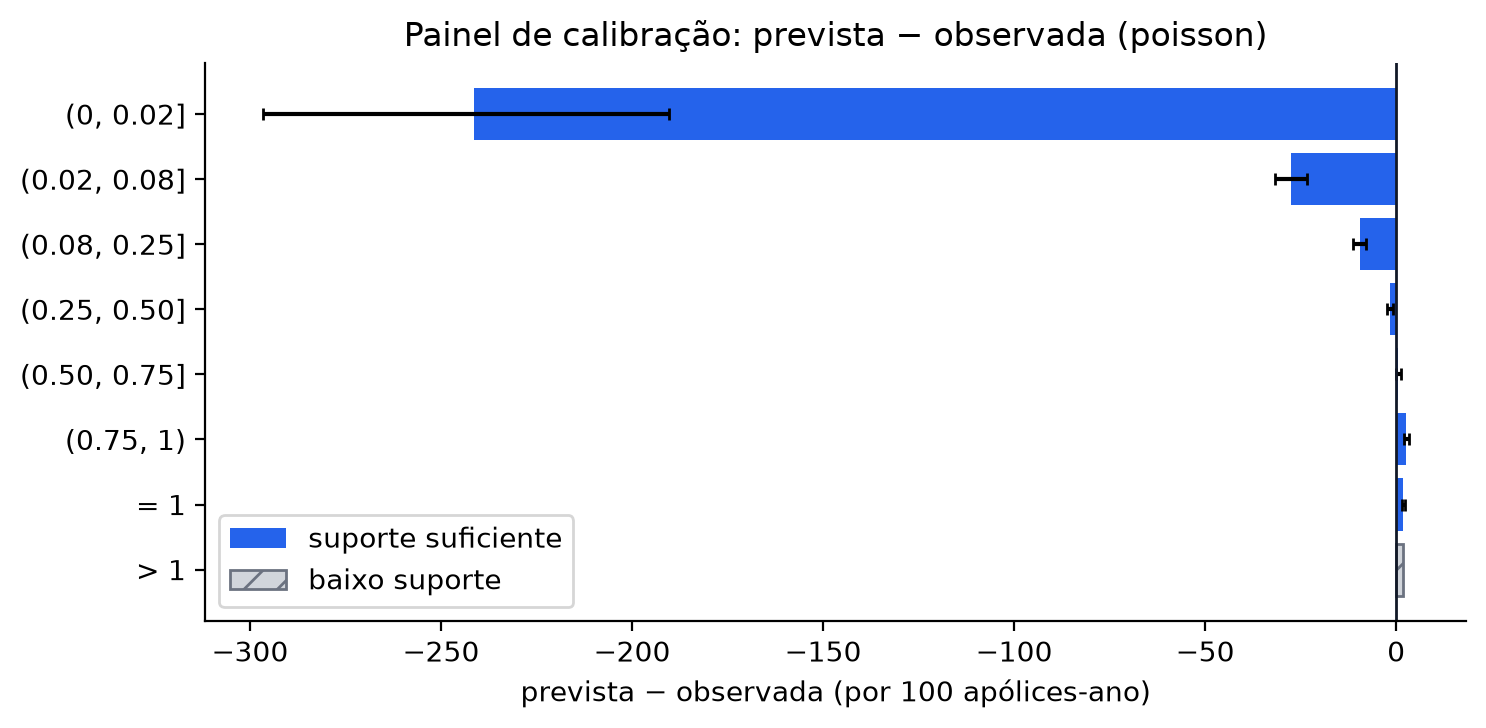

,band,test_rows,test_observed_rate,test_predicted_rate,test_diff,test_ci_low,test_ci_high,test_low_support,validation_diff,same_sign,validation_diff_inside_test_ci
0,"(0, 0.02]",2921,255.5058,14.0418,-241.4641,-296.6559,-190.3120,False,-224.7565,True,True
1,"(0.02, 0.08]",14341,39.8080,12.4017,-27.4063,-31.5899,-23.3945,False,-23.7700,True,True
2,"(0.08, 0.25]",16168,21.6239,12.0454,-9.5785,-11.3882,-7.9628,False,-11.6193,True,False
3,"(0.25, 0.50]",19859,12.9926,11.4058,-1.5867,-2.4217,-0.7464,False,-0.9274,True,True
4,"(0.50, 0.75]",13877,10.8287,11.4037,0.5749,-0.1218,1.3333,False,1.3324,True,True
5,"(0.75, 1)",9300,8.2757,10.9066,2.6308,1.9811,3.2746,False,1.6639,True,False
6,= 1,25222,6.7877,8.6875,1.8998,1.5455,2.2113,False,1.7946,True,True
7,> 1,171,9.4241,11.3144,1.8904,NaN,NaN,True,8.4641,True,False


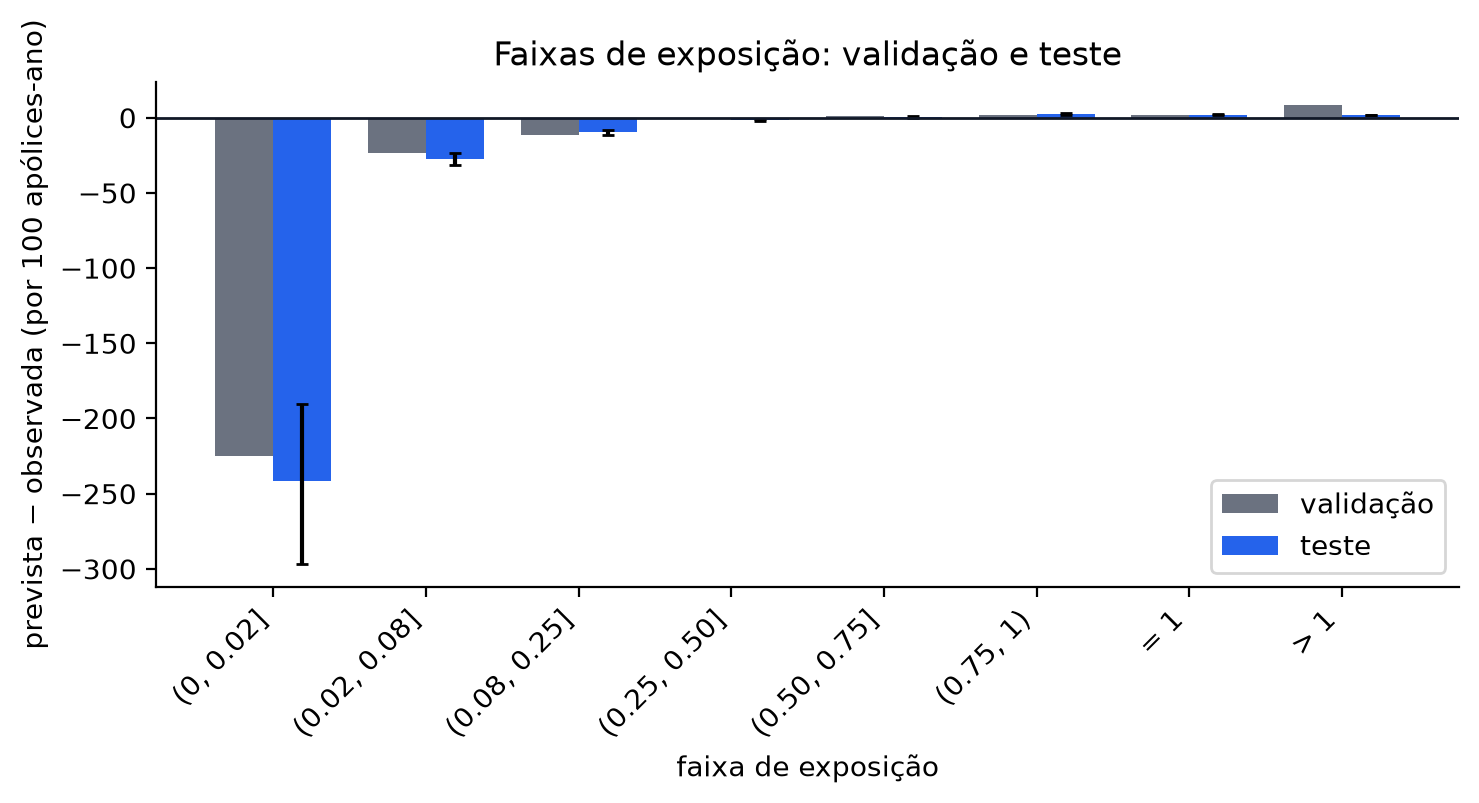

In [4]:
display(artifacts.panel_view(out5, "exposure_band", "poisson", LANG))
plots.show(plots.plot_panel(out5["panel"], LANG, "exposure_band"))
display(out5["validation_vs_test_bands"])
plots.show(plots.plot_validation_vs_test(out5["validation_vs_test_bands"],
                                         LANG))

### Insights

O desvio nas exposições curtas persiste no teste. Em `(0; 0,02]`, a taxa observada é 255,51 por 100 apólices-ano e a prevista pelo Poisson, 14,04, uma diferença de -241,5 (IC -296,7 a -190,3); em validação, a diferença foi -224,8. Em exatamente um ano, o observado é 6,79 e o previsto, 8,69 (diferença 1,90). O sinal da diferença coincide com o da validação em 8 das 8 faixas, e a diferença de validação cai dentro do intervalo de teste em 5 delas; as faixas `(0.08, 0.25]`, `(0.75, 1)` têm a diferença de validação fora do intervalo de teste. O offset fixo, portanto, subestima as exposições muito curtas e superestima as longas também no teste, e esse é um limite do modelo selecionado, que não foi recalibrado.

## 4. Calibração por idade do veículo e região

**Pergunta.** Há desvios por idade do veículo ou região que os intervalos distinguem de zero? Segmentos de baixo suporte são mostrados sem intervalo.

,segmento,registros,apólices-ano,sinistros observados,sinistros previstos,taxa observada por 100,taxa prevista por 100,prevista − observada,IC inf.,IC sup.,baixo suporte
0,0-1,19397,"7,517.4532",1233,"1,246.8921",16.4018,16.5866,0.1848,-0.7228,1.0705,False
1,11-20,26609,"15,462.0896",1179,"1,251.4327",7.6251,8.0936,0.4685,0.0130,0.8822,False
2,2-5,28885,"15,258.3124",1437,"1,426.5169",9.4178,9.3491,-0.0687,-0.5425,0.4394,False
3,21+,1270,779.1884,29,51.4280,3.7218,6.6002,2.8784,1.4026,4.1323,False
4,6-10,25698,"14,822.0495",1537,"1,465.8799",10.3697,9.8899,-0.4798,-1.0227,-0.0137,False


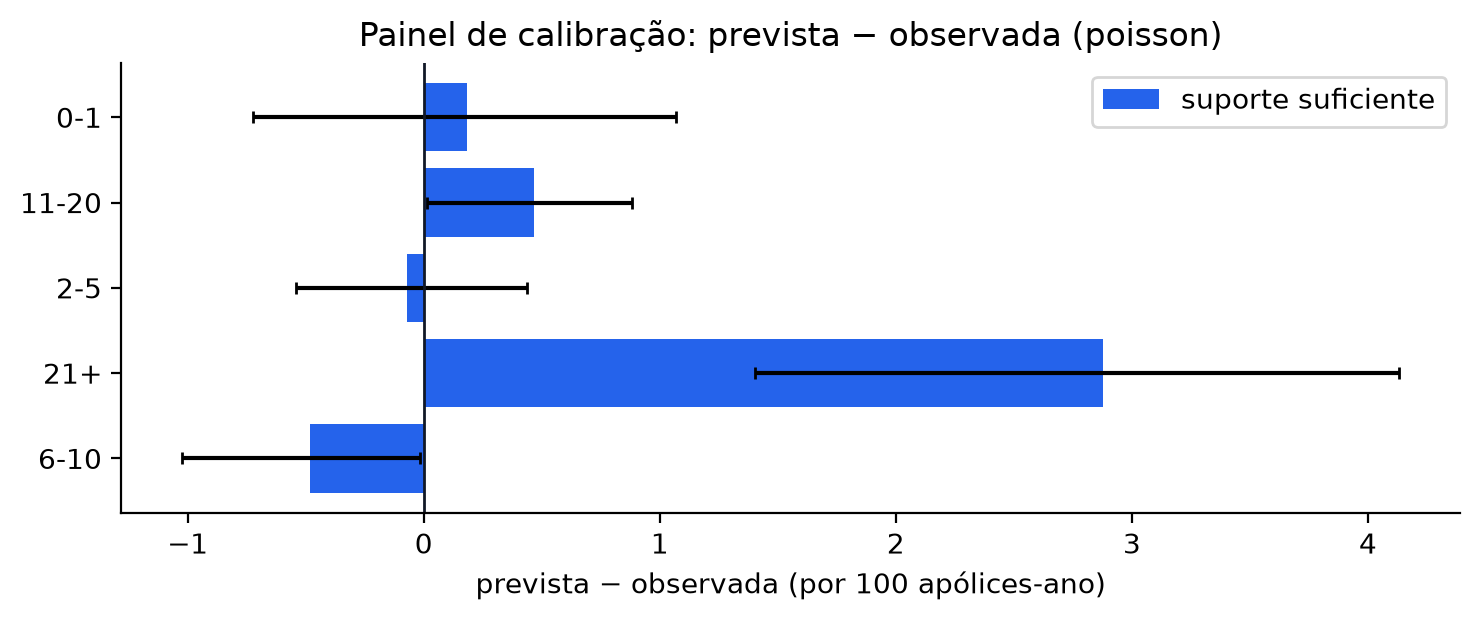

,segmento,registros,apólices-ano,sinistros observados,sinistros previstos,taxa observada por 100,taxa prevista por 100,prevista − observada,IC inf.,IC sup.,baixo suporte
0,R11,10462,"4,506.6061",607,601.0456,13.4691,13.3370,-0.1321,-1.2410,0.9702,False
1,R21,442,173.1374,19,23.0367,10.9739,13.3055,2.3315,NaN,NaN,True
2,R22,1185,559.0584,67,66.8738,11.9844,11.9619,-0.0226,-2.8395,2.8216,False
3,R23,1258,460.4391,45,42.5736,9.7733,9.2463,-0.5270,-3.5475,2.3006,False
4,R24,23983,"15,310.3704",1425,"1,365.9493",9.3074,8.9217,-0.3857,-0.8851,0.0746,False
5,R25,1579,962.0739,91,91.7180,9.4587,9.5334,0.0746,-2.2473,1.9939,False
6,R26,1571,759.1303,70,74.8381,9.2211,9.8584,0.6373,-1.6844,2.8743,False
7,R31,4090,"1,724.0599",168,181.5298,9.7444,10.5292,0.7848,-0.8655,2.2299,False
8,R41,2023,"1,265.1131",109,92.8302,8.6158,7.3377,-1.2781,-2.9260,0.1848,False
9,R42,309,171.2837,17,19.3021,9.9251,11.2691,1.3440,NaN,NaN,True


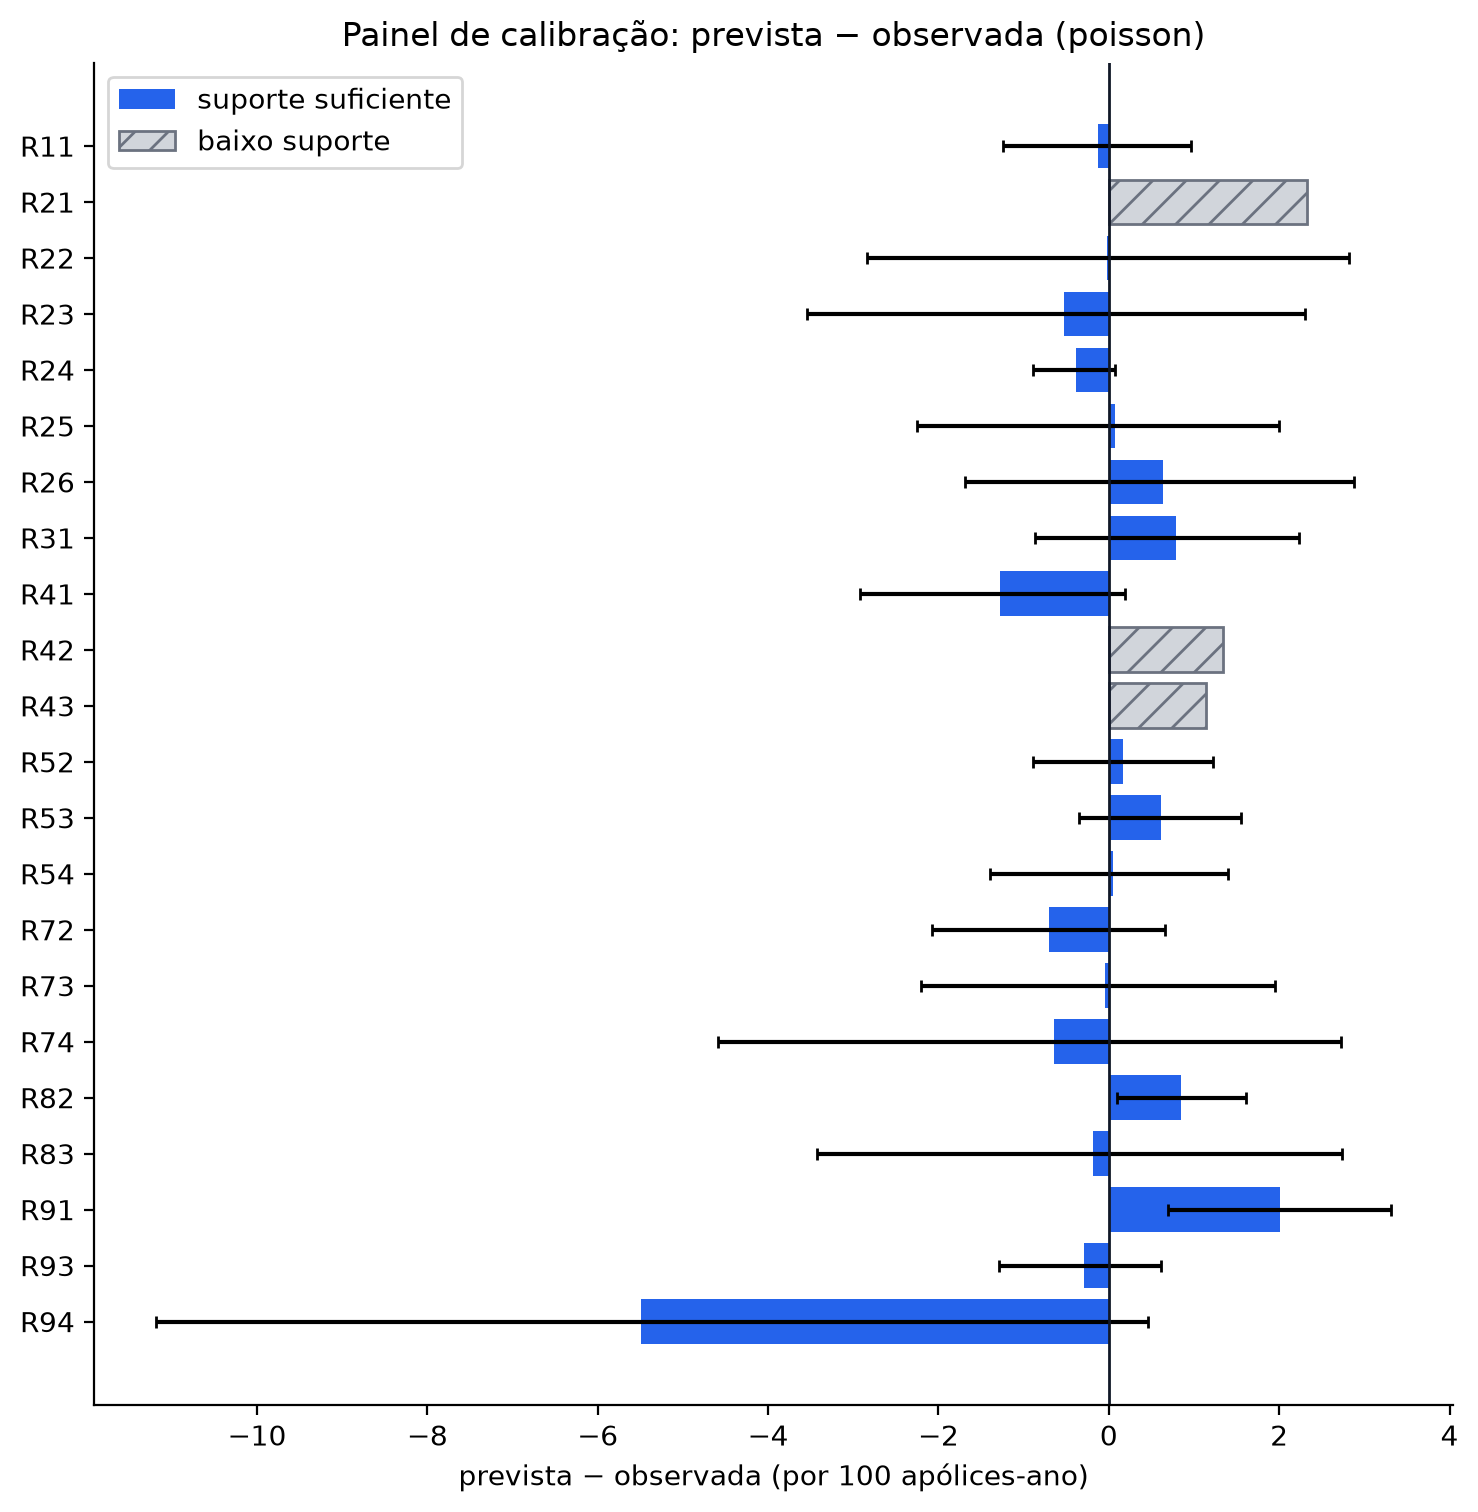

In [5]:
for family in ("vehicle_age", "region"):
    display(artifacts.panel_view(out5, family, "poisson", LANG))
    plots.show(plots.plot_panel(out5["panel"], LANG, family))

### Insights

Por idade do veículo, os intervalos distinguem de zero apenas os segmentos `11-20`, `21+`, `6-10`. Por região, apenas `R82`, `R91`; as regiões `R21`, `R42`, `R43` têm baixo suporte e não têm intervalo. Os demais segmentos têm intervalos que incluem zero. Como são muitas comparações simultâneas sem ajuste de multiplicidade, esses desvios são descritivos e não indicam, por si, falha de especificação.

## 5. Reconciliação

**Pergunta.** Cada segmentação soma os registros, a exposição e as contagens observadas e previstas ao total de cada candidato?

In [6]:
display(out5["test_reconciliation"])

,degree,population,candidate,family,indicator,segments_sum,total,ok,direct_sum_check
0,test,test,poisson,exposure_band,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
1,test,test,poisson,exposure_band,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"
2,test,test,poisson,exposure_band,observed_claims,"5,415.0000","5,415.0000",True,"5,415.0000"
3,test,test,poisson,exposure_band,predicted_claims,"5,442.1495","5,442.1495",True,"5,442.1495"
4,test,test,poisson,vehicle_age,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
5,test,test,poisson,vehicle_age,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"
6,test,test,poisson,vehicle_age,observed_claims,"5,415.0000","5,415.0000",True,"5,415.0000"
7,test,test,poisson,vehicle_age,predicted_claims,"5,442.1495","5,442.1495",True,"5,442.1495"
8,test,test,poisson,region,rows,"101,859.0000","101,859.0000",True,"101,859.0000"
9,test,test,poisson,region,exposure,"53,839.0932","53,839.0932",True,"53,839.0932"


### Insights

As 24 verificações (dois candidatos, três segmentações e quatro indicadores) foram satisfeitas: a soma dos segmentos coincide com os 101.859 registros, as 53.839,09 apólices-ano, os 5.415 sinistros observados e os previstos de cada candidato.

## 6. Conclusão e limites

**Pergunta.** O que o teste sustenta, e o que não sustenta?

In [7]:
display(pd.Series(out5["conclusion"]["primary"], name="primary"))
display(pd.Series(out5["conclusion"]["profile_cluster_bootstrap"],
                  name="profile_cluster_bootstrap"))

ci_high                                -0.0102
ci_low                                 -0.0132
d_dev_poisson_minus_global             -0.0118
verdict                       ganho_sustentado
Name: primary, dtype: object

ci_high                                -0.0103
ci_low                                 -0.0134
d_dev_poisson_minus_global             -0.0118
verdict                       ganho_sustentado
Name: profile_cluster_bootstrap, dtype: object

### Insights

O teste sustenta um ganho do Poisson com offset fixo sobre a taxa global em desvio médio de Poisson, e a escolha congelada é preservada. O ganho confirmado é no desvio médio; ele não elimina o desvio sistemático nas exposições curtas. Na calibração total, o erro absoluto pontual do Poisson é maior que o da referência, mas os intervalos individuais não permitem concluir equivalência nem diferença entre os candidatos. Os resultados valem dentro do benchmark francês, sem evidência temporal, sem `BonusMalus` (instante de medição desconhecido, Dutang & Charpentier, 2026) e sem modelos inflacionados de zeros; os intervalos são condicionados aos modelos ajustados. O modelo não é elegível para produção.

## Referências

- Dutang, C., & Charpentier, A. (2026). *CASdatasets: Insurance datasets* (R package version 1.2-1; dicionário de freMTPL2freq em https://dutangc.github.io/CASdatasets/reference/freMTPL.html). https://doi.org/10.57745/P0KHAG